In [1]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,SampleID,Path,Mask
0,train_0,emoji_dataset/train/train_0.png,emoji_dataset/train/masks/train_0.png
1,train_1,emoji_dataset/train/train_1.png,emoji_dataset/train/masks/train_1.png
2,train_2,emoji_dataset/train/train_2.png,emoji_dataset/train/masks/train_2.png
3,train_3,emoji_dataset/train/train_3.png,emoji_dataset/train/masks/train_3.png
4,train_4,emoji_dataset/train/train_4.png,emoji_dataset/train/masks/train_4.png


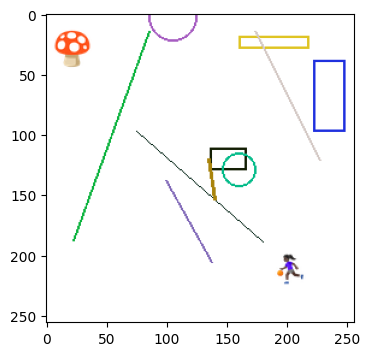

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

img1 = Image.open(df_train.Path.iloc[0])
plt.figure(figsize=(4, 4))
plt.imshow(img1)

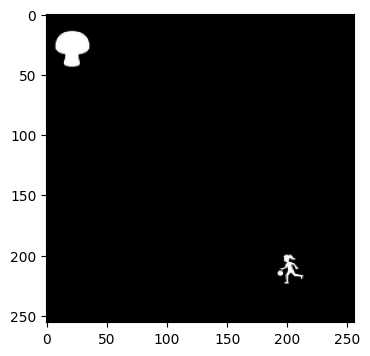

In [3]:
mask1 = Image.open(df_train.Mask.iloc[0])
plt.figure(figsize=(4, 4))
plt.imshow(mask1, cmap='grey')

In [109]:
import torch

num_epochs = 20
batch_size = 32
learning_rate = 0.005

device = torch.device("cuda")
device

device(type='cuda')

In [110]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

train_transform = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor()
])

valid_transform = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor()
])

class MyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img_path = self.df.Path.iloc[idx]
        img = Image.open(img_path)
        img = self.transform(img)
        mask_path = self.df.Mask.iloc[idx]
        mask = Image.open(mask_path)
        mask = self.transform(mask)
        return img, mask

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.2, random_state=42)

train_dataset = MyDataset(df_1, train_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = MyDataset(df_2, valid_transform)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

train_dataset[0][0][0][0][0]

tensor(1.)

In [111]:
import torch.nn as nn

class Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, 2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 8, 2, stride=2),
            nn.ReLU(),
            nn.Conv2d(8, 1, 1)
        )
    def forward(self, X):
        X = self.encoder(X)
        X = self.decoder(X)
        return X

model = Model().to(device)
criterion = nn.BCEWithLogitsLoss()
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

model

Model(
  (encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(32, 16, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(16, 8, kernel_size=(2, 2), stride=(2, 2))
    (3): ReLU()
    (4): Conv2d(8, 1, kernel_size=(1, 1), stride=(1, 1))
  )
)

In [112]:
def train(epoch):
    model.train()
    total_loss = 0
    for inputs, masks in train_loader:
        inputs, masks = inputs.to(device), masks.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, masks)
        optim.zero_grad()
        loss.backward()
        optim.step()
        total_loss += loss.item()
    print("Epoch ", epoch)
    print("Training Loss ", total_loss/len(train_loader))

def test(epoch):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, masks in test_loader:
            inputs, masks = inputs.to(device), masks.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, masks)
            total_loss += loss.item()
    print("Validation Loss ", total_loss/len(test_loader))

In [113]:
for epoch in range(1, num_epochs+1):
    train(epoch)
    test(epoch)

Epoch  1
Training Loss  0.2718713459999938
Validation Loss  0.12830584943294526
Epoch  2
Training Loss  0.12811046701512838
Validation Loss  0.11932378336787224
Epoch  3
Training Loss  0.11051828120099871
Validation Loss  0.08537096679210662
Epoch  4
Training Loss  0.0782183755777384
Validation Loss  0.06659434922039509
Epoch  5
Training Loss  0.06095437264364017
Validation Loss  0.04668976366519928
Epoch  6
Training Loss  0.04370693303644657
Validation Loss  0.03977101631462574
Epoch  7
Training Loss  0.038776256928318424
Validation Loss  0.032947278767824176
Epoch  8
Training Loss  0.034047066381103115
Validation Loss  0.03161543477326632
Epoch  9
Training Loss  0.03273579238080665
Validation Loss  0.028943569399416447
Epoch  10
Training Loss  0.03134580525128465
Validation Loss  0.03872128091752529
Epoch  11
Training Loss  0.04624097911935104
Validation Loss  0.038101821392774585
Epoch  12
Training Loss  0.0349828462655607
Validation Loss  0.029814061149954794
Epoch  13
Training Los

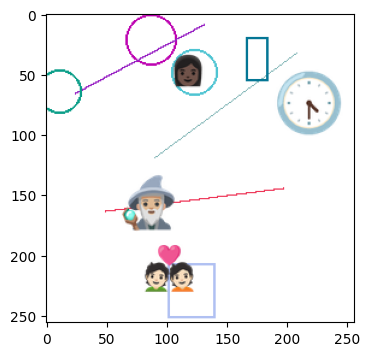

In [114]:
img1 = Image.open(df_test.Path.iloc[0])

plt.figure(figsize=(4, 4))
plt.imshow(img1)

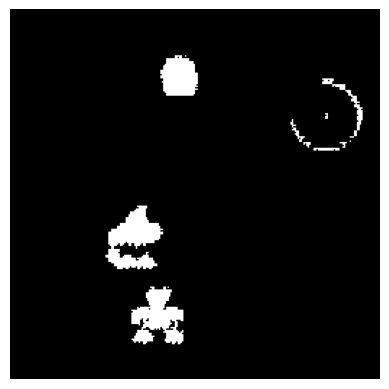

In [115]:
threshold = 0.5

model.eval()
with torch.no_grad():
    x = train_transform(img1).unsqueeze(0).to(device)  # batch dim
    prob = torch.sigmoid(model(x))
    mask = (prob > threshold).float().squeeze().cpu().numpy()

plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.show()

In [116]:
final_transform = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor()
])

class FinalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img_path = self.df.Path.iloc[idx]
        img = Image.open(img_path)
        img = self.transform(img)
        idx = self.df.SampleID.iloc[idx]
        return img, idx

final_dataset = FinalDataset(df_test, final_transform)
final_loader = DataLoader(final_dataset, batch_size=batch_size)

final_dataset[0][0][0][0][0]

tensor(1.)

In [117]:
model.eval()
rows = []

with torch.no_grad():
    for imgs, ids in final_loader:
        imgs = imgs.to(device)
        probs = torch.sigmoid(model(imgs))
        masks = (probs > threshold).float().cpu().numpy()

        for mask, sample_id in zip(masks, ids):
            mask = (mask.squeeze() * 255).astype("uint8")

            path = f"predictions/{sample_id}_mask.png"
            Image.fromarray(mask).save(path)

            rows.append({
                "SampleID": sample_id,
                "PredictedMask": path
            })

submission = pd.DataFrame(rows)
submission

,SampleID,PredictedMask
0,test_1500,predictions/test_1500_mask.png
1,test_1501,predictions/test_1501_mask.png
2,test_1502,predictions/test_1502_mask.png
3,test_1503,predictions/test_1503_mask.png
4,test_1504,predictions/test_1504_mask.png
...,...,...
495,test_1995,predictions/test_1995_mask.png
496,test_1996,predictions/test_1996_mask.png
497,test_1997,predictions/test_1997_mask.png
498,test_1998,predictions/test_1998_mask.png


In [118]:
submission.to_csv("submission.csv", index=False)